# HW：台積電 2330.TW 股價預測（Auto Regression, CRISP-DM + sklearn）

AR(p)：以前 p 天收盤價線性預測下一天：$y_t = \beta_0 + \beta_1 y_{t-1} + \dots + \beta_p y_{t-p}$

## 1. Business Understanding
- **目標**：用過去 p 天收盤價預測 2330.TW 隔日收盤價。
- **成功標準**：測試集 RMSE / MAE 低於 naive baseline（明天 = 今天），R² 高。
- 注意：股價接近 random walk，此作業重點在 AR 建模流程，不構成投資建議。

In [1]:
import gzip, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

/sessions/keen-stoic-hypatia/.local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Data Understanding
優先用 `yfinance` 抓最新資料，失敗時讀本機 `2330_TW.csv`（Yahoo Finance 2024-10 ~ 2026-10 日收盤價）。

In [2]:
try:
    import yfinance as yf
    df = yf.download('2330.TW', period='2y', progress=False)[['Close']]
    df.columns = ['Close']; df = df.reset_index()
    assert len(df) > 100
    print('Loaded from yfinance')
except Exception as e:
    print('yfinance unavailable -> local CSV.', type(e).__name__)
    df = pd.read_csv('2330_TW.csv', parse_dates=['Date'])
df = df.dropna().sort_values('Date').reset_index(drop=True)
print(df.head()); print(df.tail()); print(len(df), 'rows')

yfinance unavailable -> local CSV. ModuleNotFoundError
        Date   Close
0 2024-10-14  1045.0
1 2024-10-15  1070.0
2 2024-10-16  1045.0
3 2024-10-17  1035.0
4 2024-10-18  1085.0
          Date   Close
481 2026-10-07  2585.0
482 2026-10-08  2550.0
483 2026-10-12  2540.0
484 2026-10-13  2490.0
485 2026-10-14  2490.0
486 rows


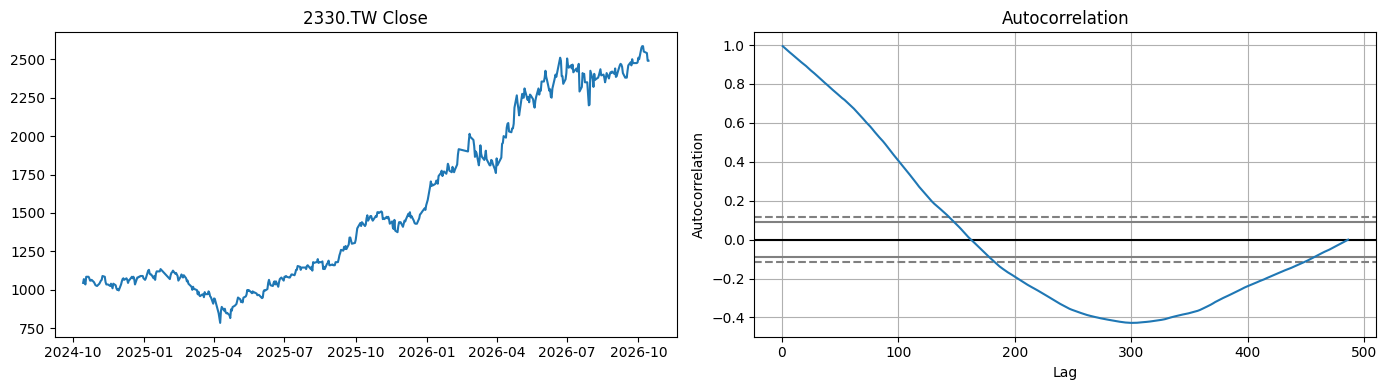

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(df['Date'], df['Close']); ax[0].set_title('2330.TW Close')
pd.plotting.autocorrelation_plot(df['Close'], ax=ax[1]); ax[1].set_title('Autocorrelation')
plt.tight_layout(); plt.show()

## 3. Data Preparation
建立 lag 特徵 `lag_1 … lag_p`，時間序列**不能隨機切分**，前 80% 訓練、後 20% 測試（避免用未來資料預測過去）。

In [4]:
def make_lags(series, p):
    d = pd.DataFrame({'y': series.values})
    for i in range(1, p + 1):
        d[f'lag_{i}'] = d['y'].shift(i)
    return d.dropna()

def split(d, ratio=0.8):
    n = int(len(d) * ratio)
    X, y = d.drop(columns='y'), d['y']
    return X.iloc[:n], X.iloc[n:], y.iloc[:n], y.iloc[n:]

def evaluate(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {'R2': r2_score(y_true, y_pred), 'MAE': mean_absolute_error(y_true, y_pred),
            'MSE': mse, 'RMSE': np.sqrt(mse)}

P = 5
d = make_lags(df['Close'], P)
X_train, X_test, y_train, y_test = split(d)
print(d.head()); print('train', X_train.shape, 'test', X_test.shape)

        y   lag_1   lag_2   lag_3   lag_4   lag_5
5  1085.0  1085.0  1035.0  1045.0  1070.0  1045.0
6  1075.0  1085.0  1085.0  1035.0  1045.0  1070.0
7  1060.0  1075.0  1085.0  1085.0  1035.0  1045.0
8  1060.0  1060.0  1075.0  1085.0  1085.0  1035.0
9  1065.0  1060.0  1060.0  1075.0  1085.0  1085.0
train (384, 5) test (97, 5)


## 4. Modeling：AR(5) with LinearRegression

In [5]:
ar = LinearRegression().fit(X_train, y_train)
print('Intercept:', round(ar.intercept_, 3))
print(pd.Series(ar.coef_, index=X_train.columns).round(4))

Intercept: -6.013
lag_1    0.9528
lag_2   -0.0744
lag_3    0.1060
lag_4   -0.0224
lag_5    0.0455
dtype: float64


## 5. Evaluation（與 naive baseline 比較）

      AR(5) train  AR(5) test  Naive test
R2         0.9949      0.5924      0.5901
MAE       20.7256     34.0577     33.8144
MSE      769.1511   2296.1315   2309.2784
RMSE      27.7336     47.9180     48.0550


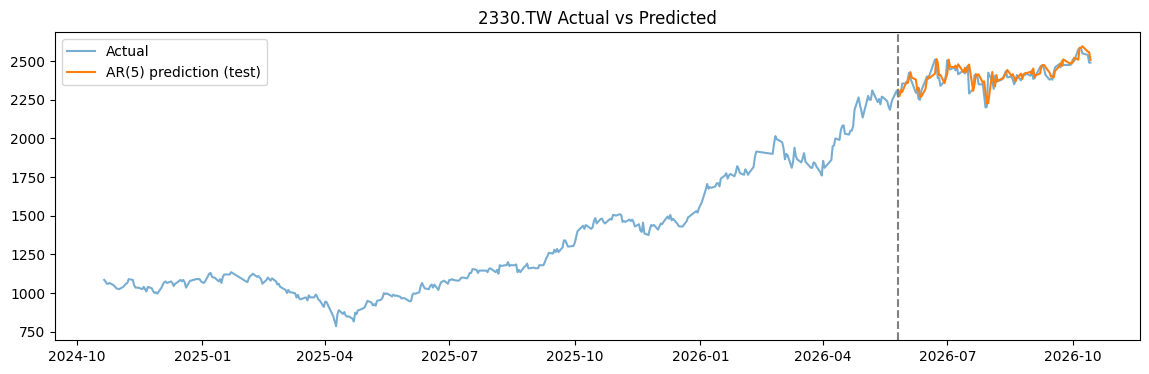

In [6]:
pred = ar.predict(X_test)
naive = X_test['lag_1']
print(pd.DataFrame({'AR(5) train': evaluate(y_train, ar.predict(X_train)),
                    'AR(5) test': evaluate(y_test, pred),
                    'Naive test': evaluate(y_test, naive)}).round(4))

dates = df['Date'].iloc[d.index]
n = len(X_train)
plt.figure(figsize=(14, 4))
plt.plot(dates, d['y'], label='Actual', alpha=.6)
plt.plot(dates.iloc[n:], pred, label='AR(5) prediction (test)')
plt.axvline(dates.iloc[n], color='gray', ls='--'); plt.legend(); plt.title('2330.TW Actual vs Predicted')
plt.show()

### 選擇 lag 數 p：training vs test curve（overfit / underfit 判斷）

    p  train RMSE  test RMSE  test R2
0   1      28.026     48.634    0.580
1   2      28.007     48.574    0.581
2   3      27.793     47.962    0.592
3   4      27.820     47.958    0.592
4   5      27.734     47.918    0.592
5   6      27.811     47.968    0.581
6   7      27.845     47.994    0.581
7   8      27.781     48.442    0.573
8   9      27.696     48.070    0.580
9  10      27.722     47.949    0.582


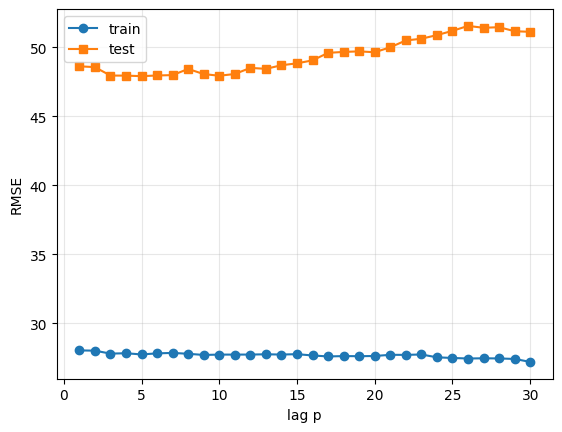

In [7]:
rows = []
for p in range(1, 31):
    Xtr, Xte, ytr, yte = split(make_lags(df['Close'], p))
    m = LinearRegression().fit(Xtr, ytr)
    rows.append({'p': p, 'train RMSE': evaluate(ytr, m.predict(Xtr))['RMSE'],
                 'test RMSE': evaluate(yte, m.predict(Xte))['RMSE'],
                 'test R2': evaluate(yte, m.predict(Xte))['R2']})
lag_df = pd.DataFrame(rows)
print(lag_df.head(10).round(3))
plt.plot(lag_df['p'], lag_df['train RMSE'], 'o-', label='train')
plt.plot(lag_df['p'], lag_df['test RMSE'], 's-', label='test')
plt.xlabel('lag p'); plt.ylabel('RMSE'); plt.legend(); plt.grid(alpha=.3); plt.show()

### Optuna 搜尋最佳 p（在訓練集內再切 validation，避免偷看 test）

In [8]:
def objective(trial):
    p = trial.suggest_int('p', 1, 30)
    Xtr, _, ytr, _ = split(make_lags(df['Close'], p))
    k = int(len(Xtr) * 0.8)
    m = LinearRegression().fit(Xtr.iloc[:k], ytr.iloc[:k])
    return evaluate(ytr.iloc[k:], m.predict(Xtr.iloc[k:]))['RMSE']

study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=0))
study.optimize(objective, n_trials=40)
best_p = study.best_params['p']
Xtr, Xte, ytr, yte = split(make_lags(df['Close'], best_p))
best = LinearRegression().fit(Xtr, ytr)
print('best p =', best_p, ' test:', {k: round(v, 4) for k, v in evaluate(yte, best.predict(Xte)).items()})

best p = 4  test: {'R2': 0.5917, 'MAE': 34.2392, 'MSE': 2299.9971, 'RMSE': np.float64(47.9583)}


## 6. Deployment：pickle + gzip，並遞迴預測未來 5 個交易日

In [9]:
with gzip.open('tsmc_ar_model.pkl.gz', 'wb') as f:
    pickle.dump({'model': best, 'p': best_p}, f)
with gzip.open('tsmc_ar_model.pkl.gz', 'rb') as f:
    b = pickle.load(f)

hist = list(df['Close'].values[-b['p']:])
future = []
for _ in range(5):
    x = pd.DataFrame([hist[::-1][:b['p']]], columns=[f'lag_{i}' for i in range(1, b['p'] + 1)])
    yhat = b['model'].predict(x)[0]
    future.append(round(yhat, 1)); hist.append(yhat)
print('Last close:', df['Close'].iloc[-1], ' next 5 days forecast:', future)

Last close: 2490.0  next 5 days forecast: [np.float64(2508.3), np.float64(2520.2), np.float64(2529.2), np.float64(2539.1), np.float64(2549.4)]


結論：AR 模型的係數集中在 lag_1（接近 1），表現與 naive baseline 相近，符合股價近似 random walk 的特性；多步預測誤差會累積，只適合短期參考。